# Homework 4 - ML Zoomcamp 2026

This homework uses the pinned 2026 lead-scoring release in the course repository. 

In [2]:
!curl -o course_lead_scoring_2026.csv https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  272k  100  272k    0     0   211k      0  0:00:01  0:00:01 --:--:--  211k


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

df = pd.read_csv('course_lead_scoring_2026.csv')
df.shape

(5000, 9)

### Data preparation

In [4]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [5]:
df.dtypes 

lead_source                  object
industry                     object
employment_status            object
location                     object
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [6]:
# split the columns by type

categorical = list(df.dtypes[df.dtypes == 'object'].index)

numerical = list(df.dtypes[df.dtypes != 'object'].index)
numerical.remove('converted')   # converted is the target, not a feature

print('categorical:', categorical)
print('numerical:', numerical)

categorical: ['lead_source', 'industry', 'employment_status', 'location']
numerical: ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


In [7]:
df[categorical] = df[categorical].fillna('NA')
df[numerical]  = df[numerical].fillna(0)

In [8]:
print(df.isnull().sum())

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64


### Split the data

In [12]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [14]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

## Question 1: ROC AUC feature importance 

ROC AUC could also be used to evaluate feature importance of numerical variables.

Let's do that

For each numerical variable, use it as score (aka prediction) and compute the AUC with the y variable as ground truth.
Use the training dataset for that
If your AUC is < 0.5, invert this variable by putting "-" in front

(e.g. -df_train['balance'])

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

* lead_score
* number_of_courses_viewed
* interaction_count
* annual_income


In [15]:
for col in numerical:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    print(col, round(auc, 3))

annual_income 0.608
number_of_courses_viewed 0.723
interaction_count 0.765
lead_score 0.788


Answer: Lead_score has the highest AUC score

# Question 2: Training the model

Apply one-hot-encoding using DictVectorizer and train the logistic regression with these parameters:

In [30]:
# Trun the Rows into dictionaries
train_dicts = df_train[categorical + numerical].to_dict(orient='records')
val_dicts = df_val[categorical + numerical].to_dict(orient='records')

In [31]:
# One hot encoding
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts) # Fit on train 
X_val = dv.transform(val_dicts) 

In [32]:
# Train

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000, solver='liblinear')

In [33]:
# Predict probability 
y_pred = model.predict_proba(X_val)[:, 1]

In [34]:
auc= roc_auc_score(y_val, y_pred)
round(auc, 3)

np.float64(0.732)

### Question 3: Precision and Recall
Now let's compute precision and recall for our model.

Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
For each threshold, compute precision and recall
Plot them


In [38]:
thresholds = np.arange(0.0, 1.01, 0.01)
scores = []

actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

for t in thresholds:
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0   # avoid divide-by-zero
    recall = tp / (tp + fn)

    scores.append((t, precision, recall))

df_scores = pd.DataFrame(scores, columns=['threshold', 'precision', 'recall'])

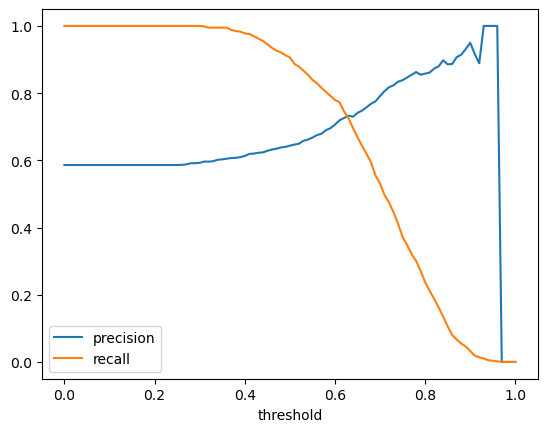

In [39]:
plt.plot(df_scores.threshold, df_scores.precision, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, label='recall')
plt.xlabel('threshold')
plt.legend()
plt.show()

In [40]:
df_valid = df_scores[(df_scores.precision > 0) | (df_scores.recall > 0)].copy()
df_valid['diff'] = (df_valid.precision - df_valid.recall).abs()
df_valid.sort_values('diff').head()

,threshold,precision,recall,diff
63,0.63,0.732759,0.725256,0.007503
62,0.62,0.725914,0.745734,0.019820
64,0.64,0.729875,0.696246,0.033629
61,0.61,0.719048,0.773038,0.053990
65,0.65,0.741021,0.668942,0.072079


 Answer: precision and recall intersects at  0.63

### Question 4: F1 score

Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both.

This is the formula for computing F1:
$$F_1 = 2 \cdot \frac{P \cdot R}{P + R}$$
Where 
P
 is precision and 
R
 is recall.
 
Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

In [42]:
df_scores['f1'] = 2* df_scores.precision * df_scores.recall / (df_scores.precision + df_scores.recall)

df_scores.sort_values('f1', ascending=False).head()

,threshold,precision,recall,f1
41,0.41,0.619048,0.976109,0.757616
42,0.42,0.620087,0.969283,0.756325
43,0.43,0.622517,0.962457,0.756032
45,0.45,0.628118,0.945392,0.754768
44,0.44,0.623608,0.955631,0.754717


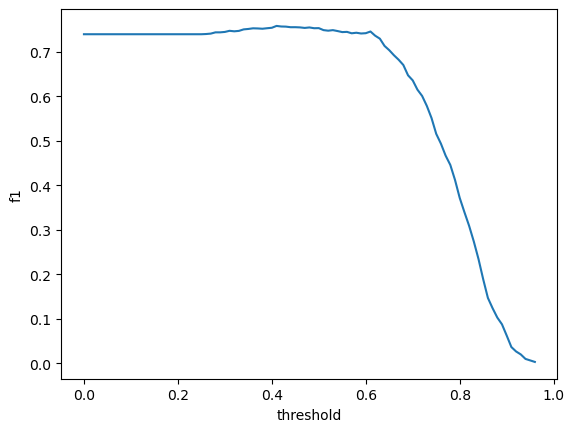

In [43]:
plt.plot(df_scores.threshold, df_scores.f1)
plt.xlabel('threshold')
plt.ylabel('f1')
plt.show()

Answer: The peak of the curve is at 0.41

## Question 5: 5-Fold CV

Use the KFold class from Scikit-Learn to evaluate our model on 5 different folds:

KFold(n_splits=5, shuffle=True, random_state=1)

* Iterate over different folds of df_full_train
* Split the data into train and validation
* Train the model on train with these parameters: LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
*se AUC to evaluate the model on validation
* 
How large is standard deviation of the scores across different folds?

In [51]:
def train(df, y, C=1.0):
    dicts = df[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y)

    return dv, model


def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred


In [52]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_tr = df_full_train.iloc[train_idx]
    df_va = df_full_train.iloc[val_idx]

    y_tr = df_tr.converted.values
    y_va = df_va.converted.values

    dv, model = train(df_tr, y_tr, C=1.0)
    y_pred_va = predict(df_va, dv, model)

    auc = roc_auc_score(y_va, y_pred_va)
    scores.append(auc)

print(np.round(scores, 3))
print('mean: %.3f  std: %.3f' % (np.mean(scores), np.std(scores)))

[0.731 0.73  0.736 0.741 0.721]
mean: 0.732  std: 0.007


Answer: the standard deviation of the scores across different folds are 0.00721. 

### Question 6: Hyperparameter Tuning

Now let's use 5-Fold cross-validation to find the best parameter C

* Iterate over the following C values: [0.000001, 0.001, 1]
* Initialize KFold with the same parameters as previously
* bUse these parameters for the model: LogisticRegression(solver='liblinear', C=C, max_iter=1000)
* Compute the mean ROC AUC as well as the std (round the mean and std to 3 decimal digits).

In [55]:
for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]

        y_tr = df_tr.converted.values
        y_va = df_va.converted.values

        dv, model = train(df_tr, y_tr, C=C)
        y_pred_va = predict(df_va, dv, model)

        scores.append(roc_auc_score(y_va, y_pred_va))

    print('C=%s  mean=%.3f  std=%.3f' % (C, np.mean(scores), np.std(scores)))


C=1e-06  mean=0.617  std=0.019
C=0.001  mean=0.749  std=0.010
C=1  mean=0.732  std=0.007


Answer: 0.001 as the highest mean AUC with 0.749